**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 7**
Análisis de Componentes Principales (PCA)

---

Equipo 29:

José Antonio Guizar Pascacio, A01174201

Isaac Antonio Gutiérrez Díaz, A01841319

Ramón Gutiérrez Lara, A01840916

Aarón Hernández Jiménez, A01642529

En esta actividad trabajarás con el archivo `automobile_dataset.csv`, basado en un conjunto de datos sobre características técnicas y especificaciones de automóviles, disponible en el repositorio UCI Machine Learning.

Los datos fueron recopilados para analizar diferentes aspectos de los vehículos y sus precios, e incluyen información sobre el fabricante, tipo de motor, dimensiones, peso, rendimiento de combustible y otras especificaciones técnicas. Los indicadores incluidos son:

* `symboling`: Nivel de riesgo del seguro del automóvil, de -3 (bajo riesgo) a +3 (alto riesgo)
* `normalized_losses`: Pérdidas normalizadas del seguro (valor numérico de la aseguradora, algunas veces faltante)
* `make`: Marca del automóvil (por ejemplo, Audi, BMW, Honda)
* `fuel_type`: Tipo de combustible (gasolina o diésel)
* `aspiration`: Tipo de aspiración del motor (normal o turbo)
* `num_doors`: Número de puertas del automóvil (dos o cuatro)
* `body_style`: Estilo de carrocería (sedán, hatchback, wagon, hardtop, convertible)
* `drive_wheels`: Tipo de tracción (fwd: delantera, rwd: trasera, 4wd: en las cuatro ruedas)
* `engine_location`: Ubicación del motor (delantero o trasero)
* `wheel_base`: Distancia entre ejes (en pulgadas)
* `length`: Largo total del automóvil (en pulgadas)
* `width`: Ancho total del automóvil (en pulgadas)
* `height`: Altura total del automóvil (en pulgadas)
* `curb_weight`: Peso del automóvil sin carga (en libras)
* `engine_type`: Tipo de motor (OHV, OHC, DOHC, etc.)
* `num_cylinders`: Número de cilindros del motor
* `engine_size`: Tamaño del motor (en cc)
* `fuel_system`: Sistema de combustible (por ejemplo, mpfi, 2bbl, 4bbl)
* `bore`: Diámetro del cilindro (en pulgadas)
* `stroke`: Carrera del pistón (en pulgadas)
* `compression_ratio`: Relación de compresión del motor
* `horsepower`: Potencia del motor (en caballos de fuerza)
* `peak_rpm`: Revoluciones máximas por minuto
* `city_mpg`: Rendimiento de combustible en ciudad (millas por galón)
* `highway_mpg`: Rendimiento de combustible en carretera (millas por galón)
* `price`: Precio del automóvil (en dólares estadounidenses) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [1]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

1. Descarga el archivo: `automobile_dataset.csv` y guarda, en un dataframe (`cars_df`), todos sus registros.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Al revisar los primeros registros, notarás que la columna `normalized_losses` contiene el símbolo `?`. Esto sugiere que se utilizó para indicar valores faltantes. Identifica todas las columnas que presentan este símbolo.
* Sustituye el símbolo `?` por valores faltantes (`NaN`) y convierte las columnas al tipo de dato adecuado. Esto es necesario porque la presencia del símbolo pudo haber hecho que pandas las interpretara como object, aunque en realidad no lo fueran.

In [2]:
cars_df = pd.read_csv('automobile_dataset.csv')
cars_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized_losses  205 non-null    object 
 2   make               205 non-null    object 
 3   fuel_type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num_doors          205 non-null    object 
 6   body_style         205 non-null    object 
 7   drive_wheels       205 non-null    object 
 8   engine_location    205 non-null    object 
 9   wheel_base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb_weight        205 non-null    int64  
 14  engine_type        205 non-null    object 
 15  num_cylinders      205 non-null    int64  
 16  engine_size        205 non

Respuesta: De acuerdo con info(), el dataframe tiene 205 registros y 26 columnas, de las cuales 12 son numéricas (7 de tipo int64 y 5 de tipo float64) y 14 son de texto (tipo object). Algunas de esas columnas de texto en realidad contienen números, lo cual se revisa a continuación.

In [3]:
cars_df.head()

,symboling,normalized_losses,make,fuel_type,aspiration,num_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.4,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.4,8.0,115,5500,18,22,17450


In [4]:
# Columnas que contienen el símbolo '?'
signo = (cars_df == '?').sum()
signo[signo > 0]

normalized_losses    41
bore                  4
stroke                4
horsepower            2
peak_rpm              2
dtype: int64

Respuesta: El símbolo ? aparece en cinco columnas: normalized_losses (41 registros), bore (4), stroke (4), horsepower (2) y peak_rpm (2). Las cinco son numéricas, pero por el símbolo pandas las leyó como texto.

In [5]:
# Sustituir '?' por NaN y convertir esas columnas a numéricas
cars_df = cars_df.replace('?', np.nan)
cols_signo = signo[signo > 0].index
cars_df[cols_signo] = cars_df[cols_signo].astype(float)
cars_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized_losses  164 non-null    float64
 2   make               205 non-null    object 
 3   fuel_type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num_doors          205 non-null    object 
 6   body_style         205 non-null    object 
 7   drive_wheels       205 non-null    object 
 8   engine_location    205 non-null    object 
 9   wheel_base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb_weight        205 non-null    int64  
 14  engine_type        205 non-null    object 
 15  num_cylinders      205 non-null    int64  
 16  engine_size        205 non

Comprobación: Después de sustituir el ? por NaN y convertir las cinco columnas a float64, el dataframe queda con 17 columnas numéricas y 9 de texto. Los conteos de no nulos ya muestran los faltantes: normalized_losses tiene 164 valores, bore y stroke 201, y horsepower y peak_rpm 203.

# Análisis exploratorio de datos (univariado)

2. Antes de iniciar con el análisis univariado, verifica si hay registros duplicados e imprime el porcentaje de faltantes por columna.
* Obtén las estadísticas descriptivas, separado las numéricas (incluye asimetría y curtosis) y las categóricas (incluye tablas de frecuencias).
* Genera histogramas para las numéricas y diagramas de barras para las categóricas.

In [6]:
print('Registros duplicados:', cars_df.duplicated().sum())
print('\nPorcentaje de faltantes por columna:')
(cars_df.isna().mean() * 100).round(2)

Registros duplicados: 0

Porcentaje de faltantes por columna:


symboling             0.00
normalized_losses    20.00
make                  0.00
fuel_type             0.00
aspiration            0.00
num_doors             0.00
body_style            0.00
drive_wheels          0.00
engine_location       0.00
wheel_base            0.00
length                0.00
width                 0.00
height                0.00
curb_weight           0.00
engine_type           0.00
num_cylinders         0.00
engine_size           0.00
fuel_system           0.00
bore                  1.95
stroke                1.95
compression_ratio     0.00
horsepower            0.98
peak_rpm              0.98
city_mpg              0.00
highway_mpg           0.00
price                 0.00
dtype: float64

Respuesta: No hay registros duplicados. Solo cinco columnas tienen faltantes: normalized_losses con 20%, bore y stroke con 1.95%, y horsepower y peak_rpm con 0.98%. El resto de las columnas, incluida la variable objetivo price, está completo.

In [7]:
num_cols = cars_df.select_dtypes(include='number').columns
cat_cols = cars_df.select_dtypes(exclude='number').columns

# Estadísticas descriptivas de las numéricas con asimetría y curtosis
desc_num = cars_df[num_cols].describe().T
desc_num['skew'] = cars_df[num_cols].skew()
desc_num['kurtosis'] = cars_df[num_cols].kurt()
desc_num.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
symboling,205.0,0.83,1.25,-2.00,0.00,1.00,2.00,3.00,0.21,-0.68
normalized_losses,164.0,122.00,35.44,65.00,94.00,115.00,150.00,256.00,0.77,0.53
wheel_base,205.0,98.76,6.02,86.60,94.50,97.00,102.40,120.90,1.05,1.02
length,205.0,174.05,12.34,141.10,166.30,173.20,183.10,208.10,0.16,-0.08
width,205.0,65.91,2.15,60.30,64.10,65.50,66.90,72.30,0.90,0.70
height,205.0,53.72,2.44,47.80,52.00,54.10,55.50,59.80,0.06,-0.44
curb_weight,205.0,2555.57,520.68,1488.00,2145.00,2414.00,2935.00,4066.00,0.68,-0.04
num_cylinders,205.0,4.38,1.08,2.00,4.00,4.00,4.00,12.00,2.82,13.71
engine_size,205.0,126.91,41.64,61.00,97.00,120.00,141.00,326.00,1.95,5.31
bore,201.0,3.33,0.27,2.54,3.15,3.31,3.59,3.94,0.02,-0.83


In [8]:
cars_df[cat_cols].describe().T

,count,unique,top,freq
make,205,22,toyota,32
fuel_type,205,2,gas,185
aspiration,205,2,std,168
num_doors,205,2,four,116
body_style,205,5,sedan,96
drive_wheels,205,3,fwd,120
engine_location,205,2,front,202
engine_type,205,7,ohc,148
fuel_system,205,8,mpfi,94


In [9]:
# Tablas de frecuencia de las variables categóricas
for col in cat_cols:
    print(cars_df[col].value_counts().to_frame(), '\n')

               count
make                
toyota            32
nissan            18
mazda             17
mitsubishi        13
honda             13
volkswagen        12
subaru            12
peugot            11
volvo             11
dodge              9
mercedes-benz      8
bmw                8
audi               7
plymouth           7
saab               6
porsche            5
isuzu              4
jaguar             3
chevrolet          3
alfa-romero        3
renault            2
mercury            1 

           count
fuel_type       
gas          185
diesel        20 

            count
aspiration       
std           168
turbo          37 

           count
num_doors       
four         116
two           89 

             count
body_style        
sedan           96
hatchback       70
wagon           25
hardtop          8
convertible      6 

              count
drive_wheels       
fwd             120
rwd              76
4wd               9 

                 count
engine_location     

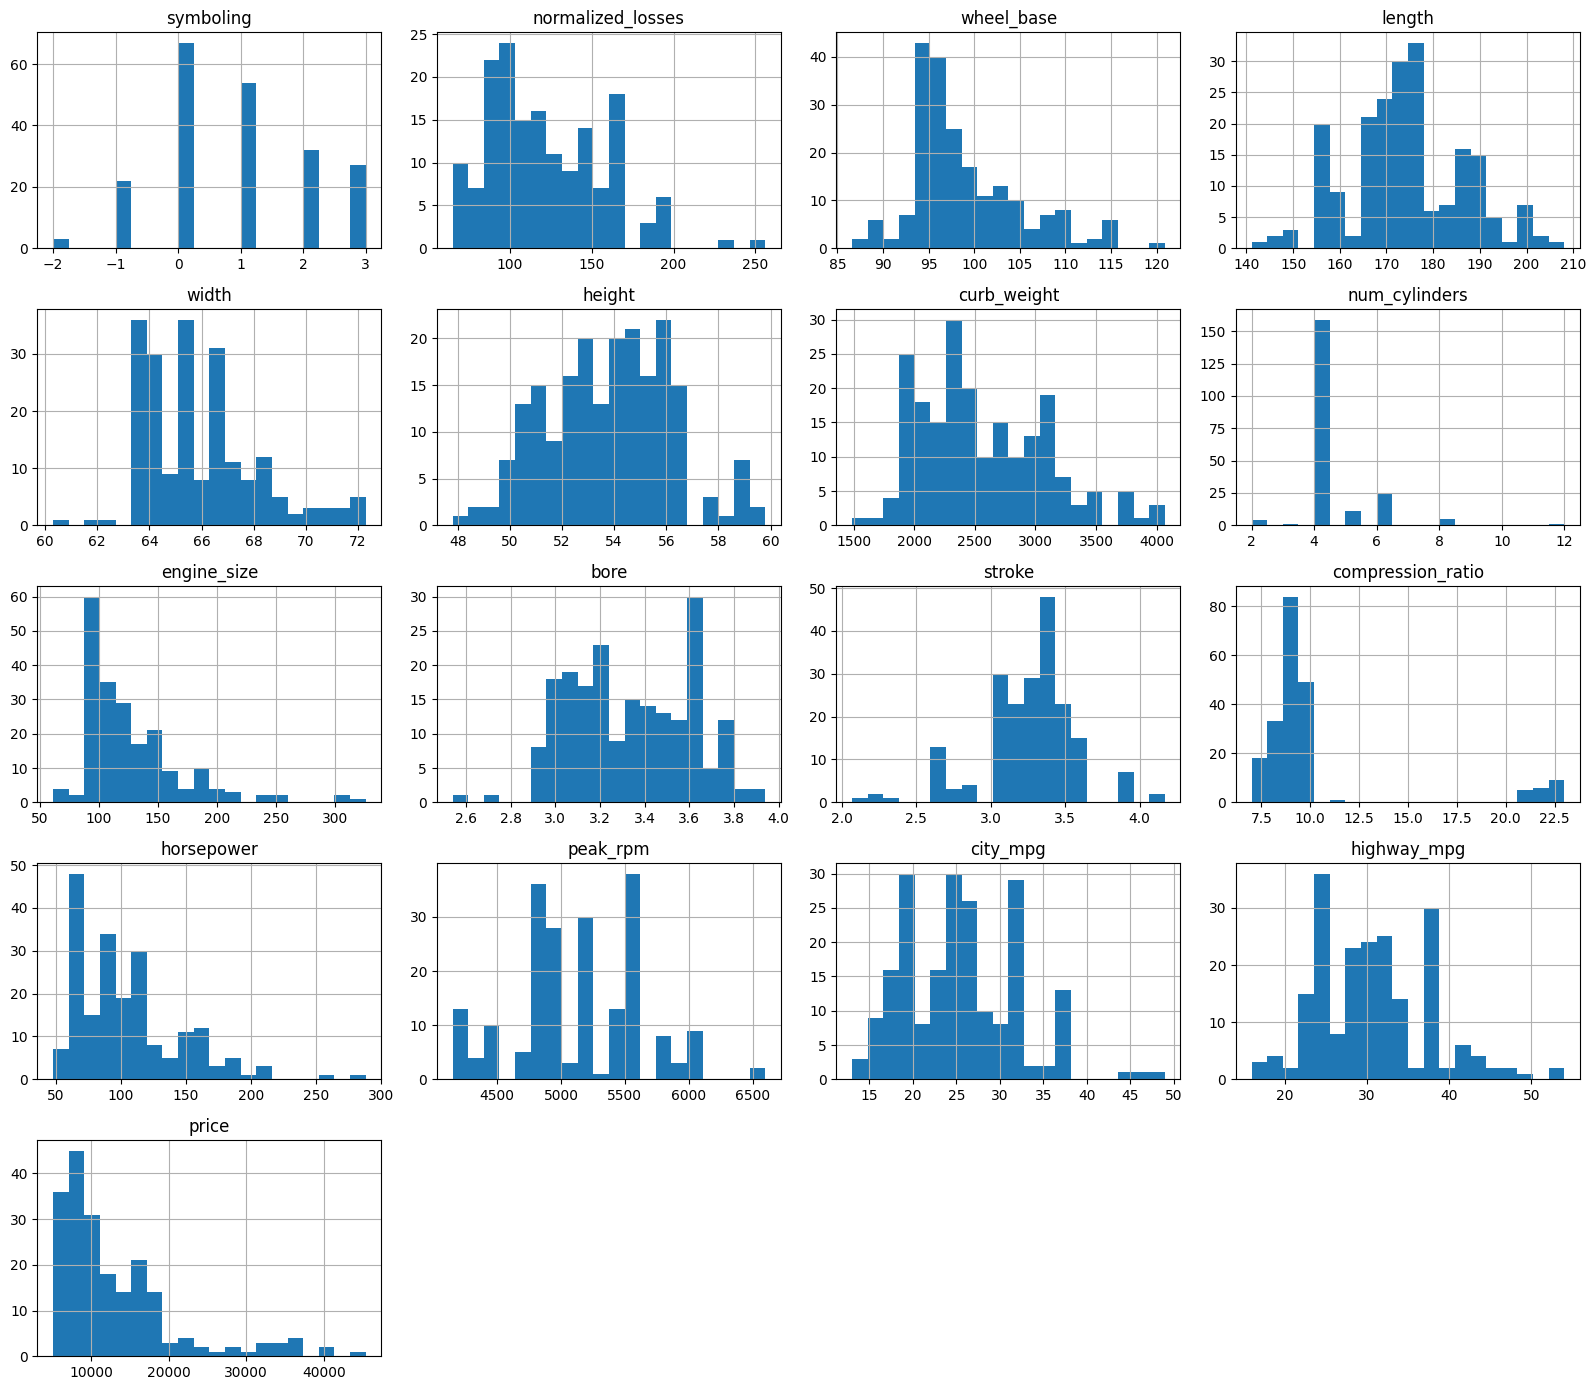

In [10]:
# Histogramas de las variables numéricas
cars_df[num_cols].hist(bins=20, figsize=(16, 14))
plt.tight_layout()
plt.show()

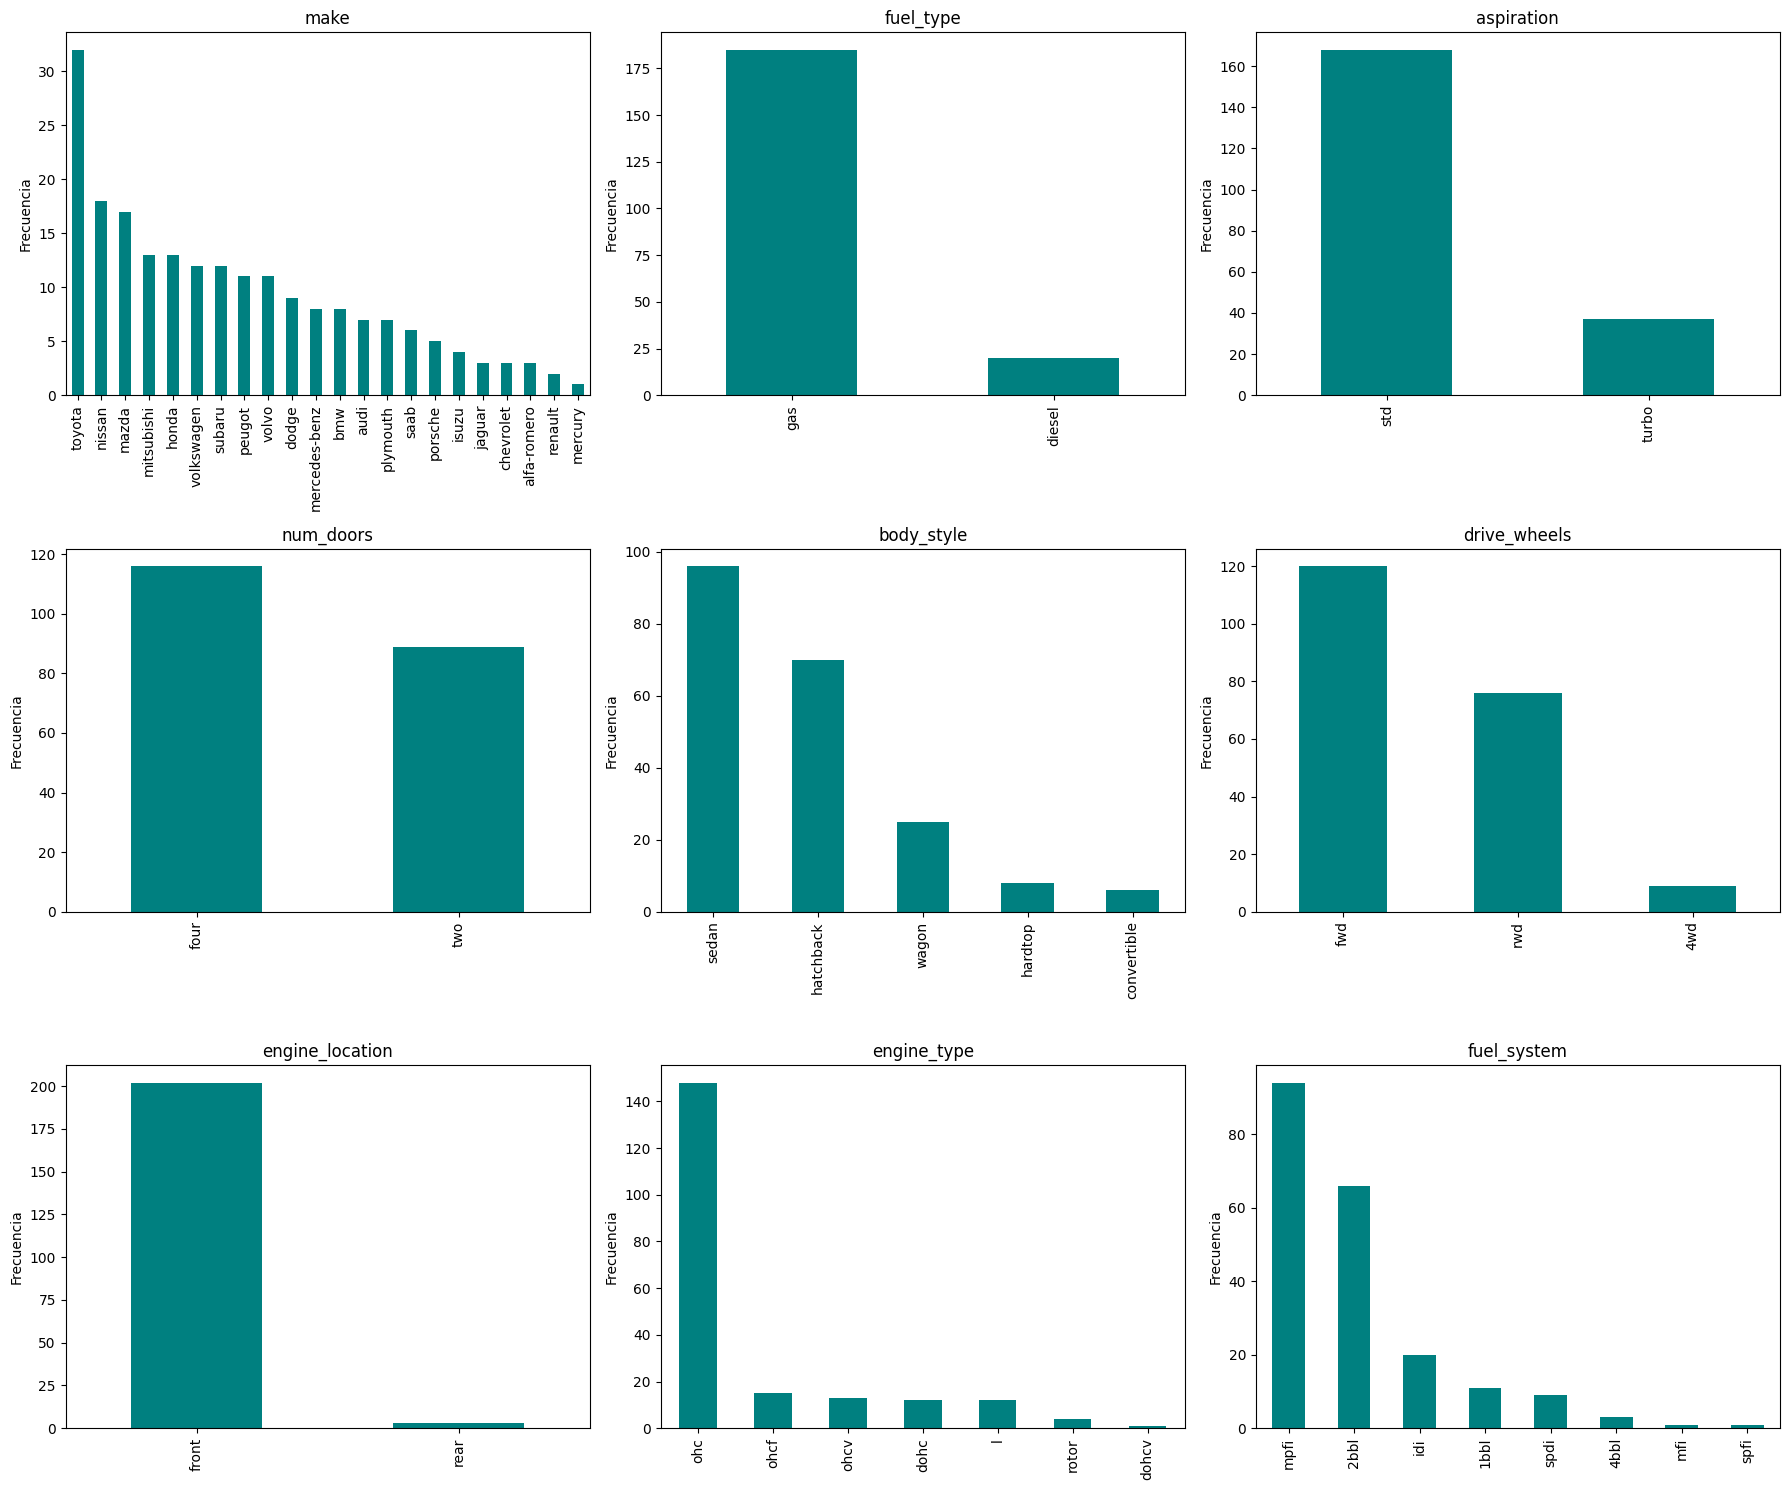

In [11]:
# Diagramas de barras de las variables categóricas
fig, axes = plt.subplots(3, 3, figsize=(18, 15))
for ax, col in zip(axes.flatten(), cat_cols):
    cars_df[col].value_counts().plot(kind='bar', ax=ax, color='teal')
    ax.set_title(col)
    ax.set_xlabel('')
    ax.set_ylabel('Frecuencia')
plt.tight_layout()
plt.show()

Análisis: La variable price tiene sesgo positivo (skew de 1.84), con una mediana de 10,295 USD y valores de hasta 45,400 USD, es decir, la mayoría de los autos son económicos y pocos son de lujo. engine_size (1.95), horsepower (1.39) y num_cylinders (2.82, con curtosis de 13.71) también tienen cola a la derecha. compression_ratio muestra dos grupos separados: los autos de gasolina tienen relaciones de 7 a 11.5 y los diésel de 21 a 23. length, height, bore y peak_rpm son casi simétricas.

En las categóricas predominan los autos de gasolina (185 de 205), la aspiración estándar (168), los estilos sedan (96) y hatchback (70), la tracción delantera (120), el motor delantero (202 de 205) y el tipo de motor ohc (148). Toyota es la marca con más registros (32).

# Análisis exploratorio de datos (bivariado)

3. Genera algunos gráficos bivariados para familiarizarte con el conjunto de datos:
* Gráfico de barras apiladas normalizadas que muestra la distribución de los tipos de tracción para cada fabricante.
* Diagrama de cajas para visualizar cómo se distribuye el precio de los automóviles según el estilo de carrocería. Esto permitirá comparar la mediana, los cuartiles y la presencia de valores atípicos entre los diferentes tipos de carrocería.
* Gráfico de barras que muestre los 10 automóviles más caros, ordenados de mayor a menor precio, con cada barra diferenciada con color por fabricante.
* Diagrama de dispersión para explorar la relación entre el tamaño del motor y el precio de los automóviles. Diferencia con colores los puntos según el tipo de aspiración y con el tamaño de los puntos el número de puertas.

**Nota.** Debes incluir en cada gráfico una conclusión de lo observado.

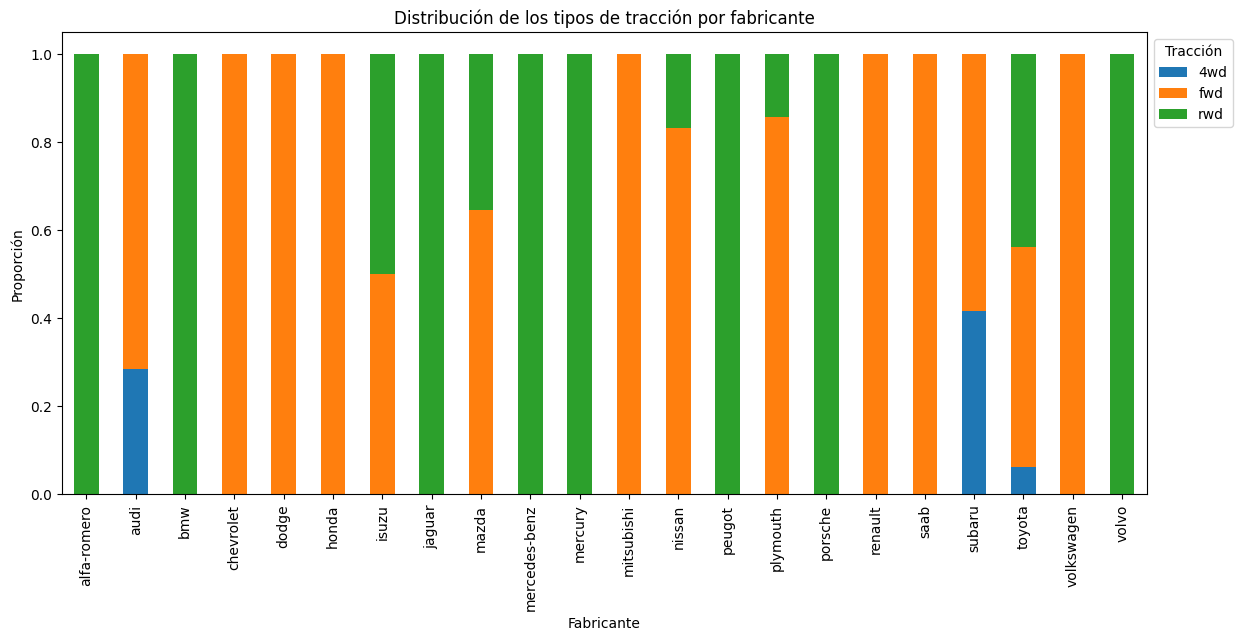

In [12]:
# Barras apiladas normalizadas: tipo de tracción por fabricante
traccion = pd.crosstab(cars_df['make'], cars_df['drive_wheels'], normalize='index')
traccion.plot(kind='bar', stacked=True, figsize=(14, 6))
plt.title('Distribución de los tipos de tracción por fabricante')
plt.xlabel('Fabricante')
plt.ylabel('Proporción')
plt.legend(title='Tracción', bbox_to_anchor=(1, 1))
plt.show()

Conclusión: Ocho marcas usan solo tracción trasera, entre ellas las de gama alta como bmw, mercedes-benz, jaguar, porsche y volvo. Otras siete, como chevrolet, dodge, honda, mitsubishi y volkswagen, usan solo tracción delantera. La tracción en las cuatro ruedas es poco común y solo aparece en subaru (42%), audi (29%) y toyota (6%). Toyota es la única marca que combina los tres tipos.

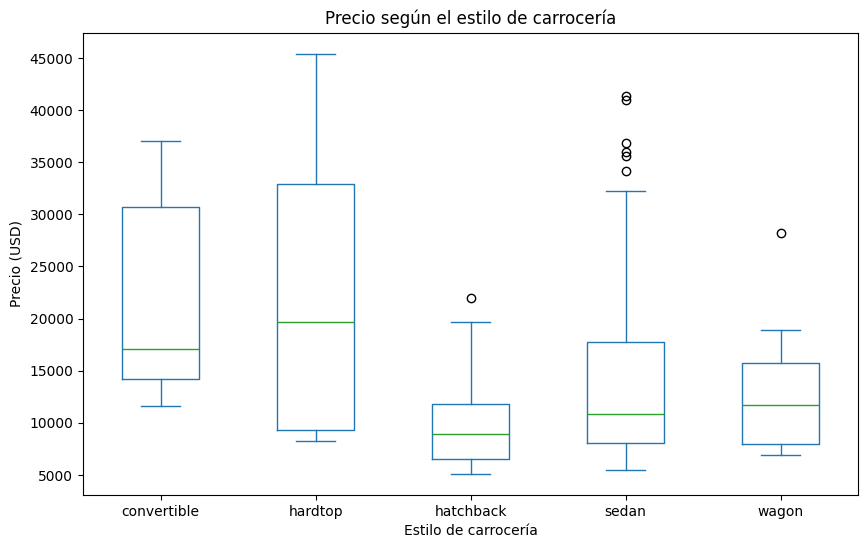

In [13]:
# Diagrama de cajas: precio según el estilo de carrocería
cars_df.plot(kind='box', column='price', by='body_style', figsize=(10, 6))
plt.title('Precio según el estilo de carrocería')
plt.xlabel('Estilo de carrocería')
plt.ylabel('Precio (USD)')
plt.show()

Conclusión: hardtop y convertible tienen las medianas más altas (19,688 y 17,084 USD) y las cajas más amplias, aunque son pocos autos (8 y 6). hatchback es el estilo más barato, con mediana de 8,897 USD y menor dispersión. sedan tiene una mediana de 10,846 USD, pero presenta seis valores atípicos entre 34,184 y 41,315 USD, que corresponden a sedanes de lujo de bmw, jaguar y mercedes-benz. wagon tiene un atípico cerca de 28,000 USD y hatchback uno cerca de 22,000 USD.

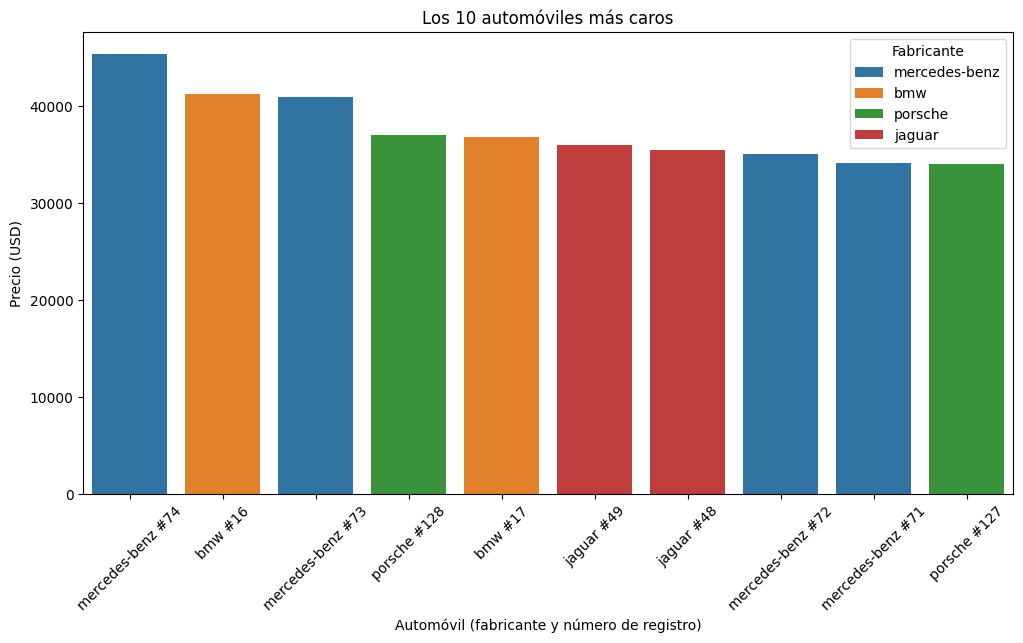

In [14]:
# Los 10 automóviles más caros, de mayor a menor precio
top10 = cars_df.nlargest(10, 'price')
etiquetas = top10['make'] + ' #' + top10.index.astype(str)

plt.figure(figsize=(12, 6))
sns.barplot(x=etiquetas, y=top10['price'], hue=top10['make'])
plt.title('Los 10 automóviles más caros')
plt.xlabel('Automóvil (fabricante y número de registro)')
plt.ylabel('Precio (USD)')
plt.xticks(rotation=45)
plt.legend(title='Fabricante')
plt.show()

Conclusión: Los 10 autos más caros pertenecen solo a cuatro marcas de lujo: mercedes-benz (4), bmw (2), porsche (2) y jaguar (2). El más caro es un mercedes-benz hardtop de 45,400 USD y el décimo un porsche de 34,028 USD. Todos tienen motores de 6 a 12 cilindros y 155 hp o más, lo que anticipa que el tamaño y la potencia del motor influyen mucho en el precio.

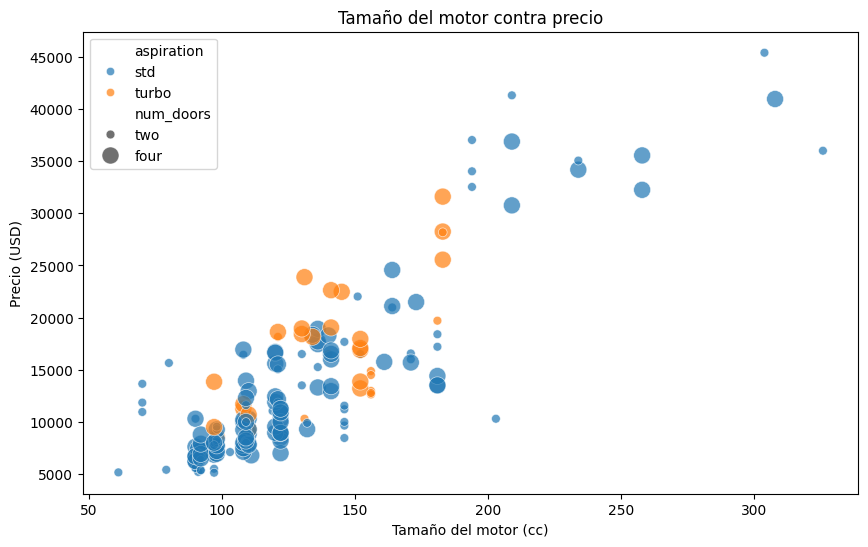

In [15]:
# Dispersión: tamaño del motor contra precio, color por aspiración y tamaño por número de puertas
plt.figure(figsize=(10, 6))
sns.scatterplot(data=cars_df, x='engine_size', y='price', hue='aspiration',
                size='num_doors', sizes={'two': 40, 'four': 150}, alpha=0.7)
plt.title('Tamaño del motor contra precio')
plt.xlabel('Tamaño del motor (cc)')
plt.ylabel('Precio (USD)')
plt.show()

Conclusión: Existe una relación positiva y fuerte entre el tamaño del motor y el precio (correlación de 0.86): a mayor motor, mayor precio. Los autos turbo se concentran en motores medianos, de 97 a 183 cc, y suelen costar más que los de aspiración estándar con motor parecido, con una mediana de 14,869 USD contra 9,594 USD. Los motores de más de 200 cc y los precios mayores a 40,000 USD son todos de aspiración estándar. El número de puertas no muestra un patrón claro, ya que hay puntos grandes y chicos en todo el rango.

4. Genera un mapa de calor de la matriz de correlación entre las variables numéricas del conjunto de datos, mostrando los valores de correlación en cada celda.
* ¿Cuáles son las tres variables más correlacionadas con el precio?

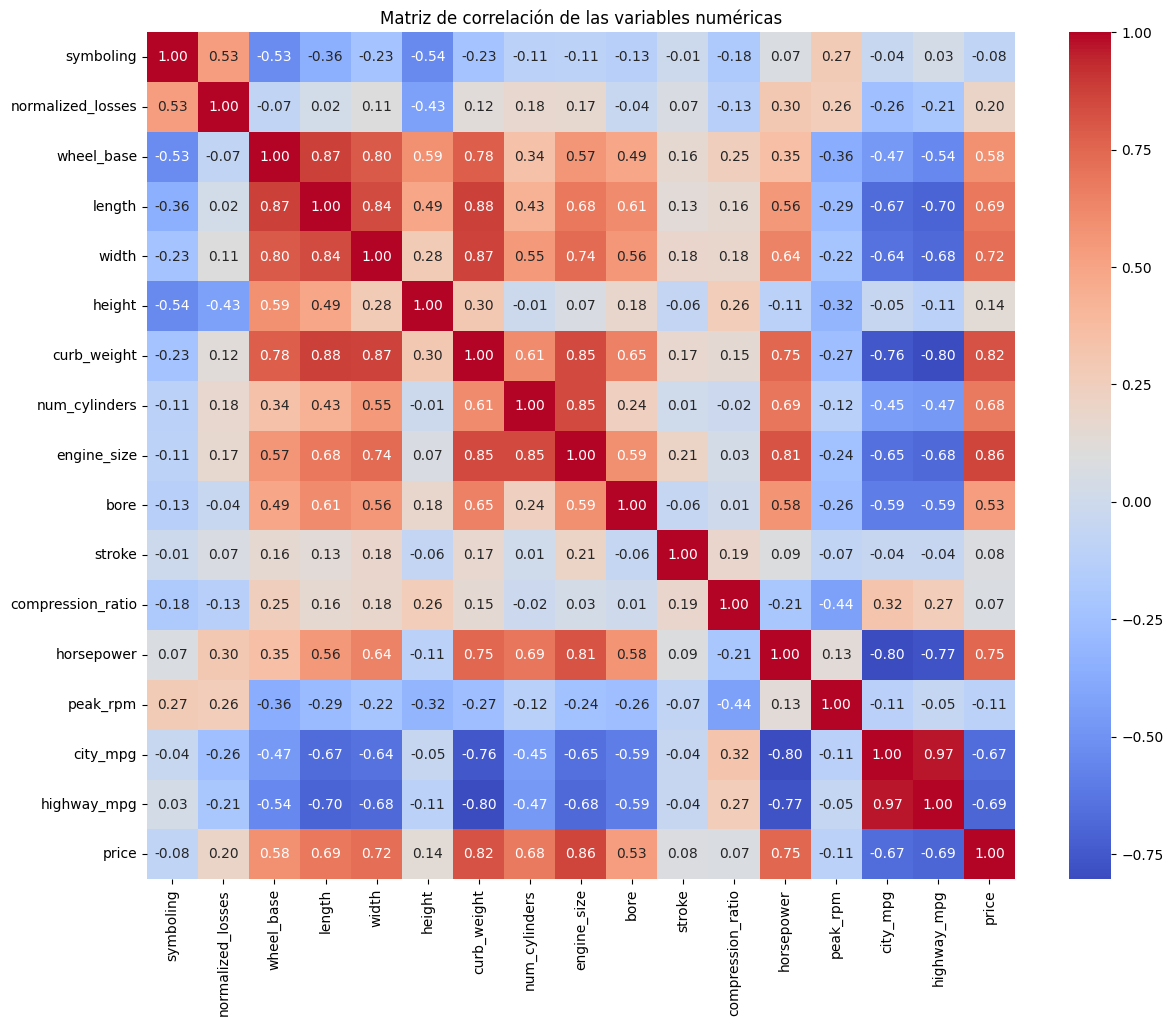

In [16]:
corr = cars_df[num_cols].corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Matriz de correlación de las variables numéricas')
plt.show()

In [17]:
# Variables más correlacionadas con el precio (en valor absoluto)
corr['price'].drop('price').sort_values(key=abs, ascending=False).head(3)

engine_size    0.860343
curb_weight    0.819817
horsepower     0.749844
Name: price, dtype: float64

Respuesta: Las tres variables más correlacionadas con el precio son engine_size (0.86), curb_weight (0.82) y horsepower (0.75). Las tres tienen correlación positiva, es decir, los autos con motor más grande, más pesados y más potentes son más caros. Les siguen width (0.72) y, con signo negativo, highway_mpg (-0.69) y city_mpg (-0.67).

En el mapa también se ven pares de predictores muy correlacionados entre sí, como city_mpg con highway_mpg (0.97), length con curb_weight (0.88) y wheel_base con length (0.87).

En el análisis de correlación se observa que existen muchos pares de variables altamente correlacionadas, lo que puede afectar el desempeño de los modelos de regresión. PCA resulta útil no solo para reducir la dimensionalidad, sino también porque los componentes principales son ortogonales entre sí, es decir, tienen correlación cero, evitando problemas de multicolinealidad. Esto lo podrás comprobrar más adelante.

# Ingeniería de características

5. Realiza las siguientes operaciones de ingeniería de características en las variables numéricas:
* Considera `price` como la variable objetivo y guárdala en `y`. Separa los predictores numéricos en `X`. Con base en estos datos, ¿cuántos componentes principales se generarán al aplicar PCA?
* Aplica `SimpleImputer` sobre `X` para tratar los valores faltantes, justificando la estrategia de imputación seleccionada.
* Realiza el escalamiento del conjunto `X` ya imputado, para que todas las variables contribuyan equitativamente y ninguna domine el análisis por tener una escala mayor.

PCA está diseñado principalmente para variables numéricas y funciona encontrando combinaciones lineales de las variables originales que capturan la mayor varianza en los datos. Normalmente se recomienda eliminar las variables categóricas antes de aplicar PCA y luego concatenarlas nuevamente con los resultados de PCA si se desea.

In [18]:
y = cars_df['price']
X = cars_df[num_cols].drop(columns='price')
print('Predictores numéricos en X:', X.shape[1])
print('Registros:', X.shape[0])

Predictores numéricos en X: 16
Registros: 205


Respuesta: X tiene 16 predictores numéricos y 205 registros. PCA genera tantos componentes como el menor de estos dos números, por lo que se generarán 16 componentes principales.

In [19]:
# Imputación con la mediana
imputer = SimpleImputer(strategy='median')
X_imp = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)
print('Faltantes después de imputar:', X_imp.isna().sum().sum())

Faltantes después de imputar: 0


Justificación: Se usa la mediana porque varias de las variables con faltantes tienen distribuciones asimétricas o con atípicos, por ejemplo normalized_losses (skew de 0.77 y máximo de 256), horsepower (skew de 1.39) y stroke (curtosis de 2.07). A diferencia de la media, la mediana no se ve afectada por esos valores extremos. Además, los faltantes son pocos (20% en normalized_losses y menos de 2% en las demás), por lo que la imputación no distorsiona las distribuciones.

In [20]:
# Escalamiento (media 0 y desviación estándar 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imp)
pd.DataFrame(X_scaled, columns=X.columns).describe().T[['mean', 'std']].round(2)

,mean,std
symboling,0.0,1.0
normalized_losses,0.0,1.0
wheel_base,-0.0,1.0
length,0.0,1.0
width,0.0,1.0
height,-0.0,1.0
curb_weight,0.0,1.0
num_cylinders,-0.0,1.0
engine_size,0.0,1.0
bore,0.0,1.0


Comprobación: Después de StandardScaler todas las variables tienen media 0 y desviación estándar 1. Así, ninguna domina el PCA por su escala, como pasaría con curb_weight (miles de libras) frente a bore (alrededor de 3 pulgadas).

6. Aplica `PCA` a los datos escalados para proyectarlos en el nuevo espacio de vectores.
* Asigna nombres descriptivos a los componentes principales en el dataframe resultante, utilizando la convención PC1, PC2, PC3, y así sucesivamente.
* Genera un mapa de calor con la matriz de correlaciones de los componentes principales para verificar que sean independientes entre sí.

In [21]:
pca = PCA()
componentes = pca.fit_transform(X_scaled)
pca_df = pd.DataFrame(componentes, columns=[f'PC{i + 1}' for i in range(componentes.shape[1])])
pca_df.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16
0,-0.918474,-2.397150,-0.410501,1.416623,-1.822817,1.203190,0.369729,0.288788,-1.088415,-0.347735,-0.474581,0.267610,-0.273617,0.362346,0.185204,0.003853
1,-0.918474,-2.397150,-0.410501,1.416623,-1.822817,1.203190,0.369729,0.288788,-1.088415,-0.347735,-0.474581,0.267610,-0.273617,0.362346,0.185204,0.003853
2,0.634430,-1.372747,0.872496,0.998222,1.834717,-0.774751,-0.515065,1.370499,-1.130802,-1.013703,0.502983,0.657052,0.174955,-0.008520,0.118635,-0.111688
3,-0.361470,-0.919214,0.451578,-1.489124,-0.269938,-0.789900,0.000484,0.400032,0.293338,0.168137,0.039239,-0.022832,-0.078891,-0.391786,0.009265,0.053641
4,1.172393,-1.794960,0.183773,-1.083812,0.113486,-0.861858,-0.353900,0.870186,0.015429,-0.447054,-0.055376,-0.416053,-0.049431,0.079357,-0.198402,0.046303


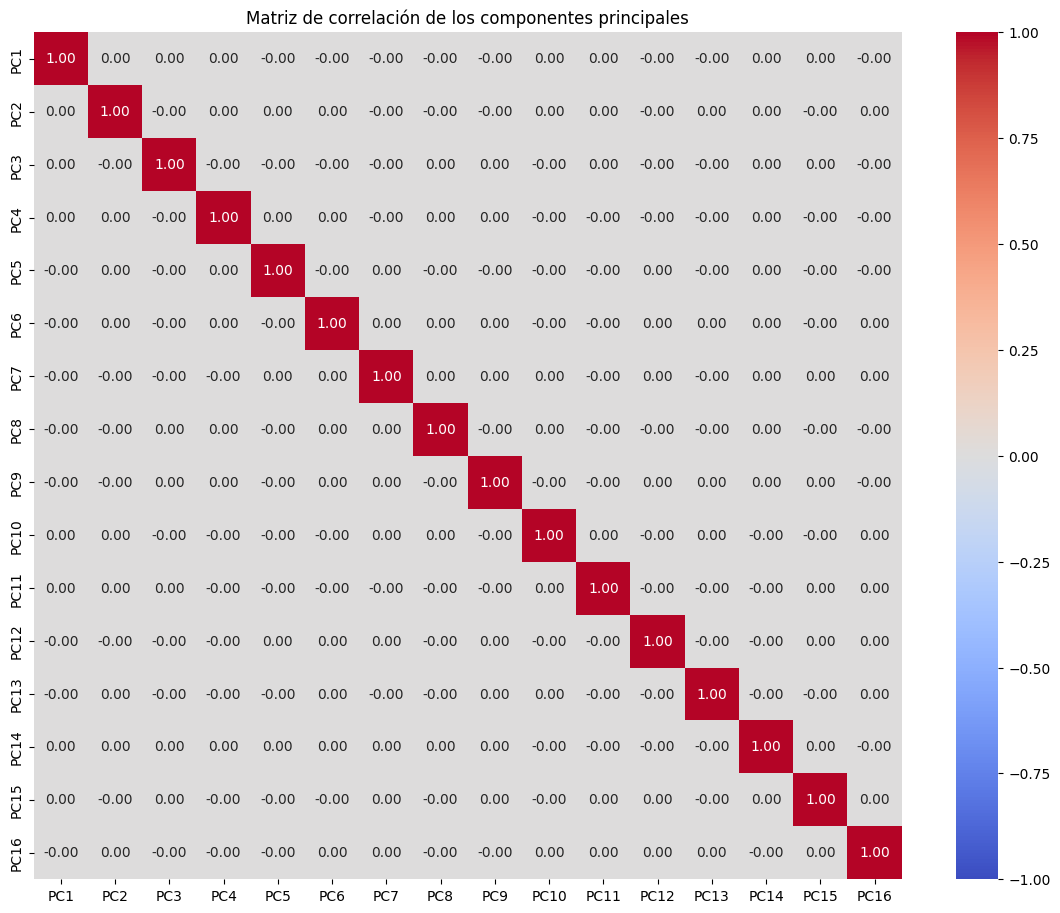

In [22]:
plt.figure(figsize=(14, 11))
sns.heatmap(pca_df.corr().round(2), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matriz de correlación de los componentes principales')
plt.show()

Comprobación: La matriz de correlación de los componentes tiene 1 en la diagonal y 0 en todas las demás celdas, por lo que los 16 componentes son independientes entre sí. Con esto se elimina la multicolinealidad que se observó entre las variables originales.

7. Obtén el porcentaje de varianza explicada por cada componente.
* Grafica la curva de varianza acumulada para determinar el número mínimo de componentes principales que explican más del 90% de la varianza total.

In [23]:
# Porcentaje de varianza explicada por cada componente
varianza = pd.Series(pca.explained_variance_ratio_ * 100, index=pca_df.columns)
varianza.round(2)

PC1     44.55
PC2     17.93
PC3      8.58
PC4      6.44
PC5      5.74
PC6      4.78
PC7      3.25
PC8      2.73
PC9      1.94
PC10     1.55
PC11     0.75
PC12     0.63
PC13     0.51
PC14     0.35
PC15     0.16
PC16     0.12
dtype: float64

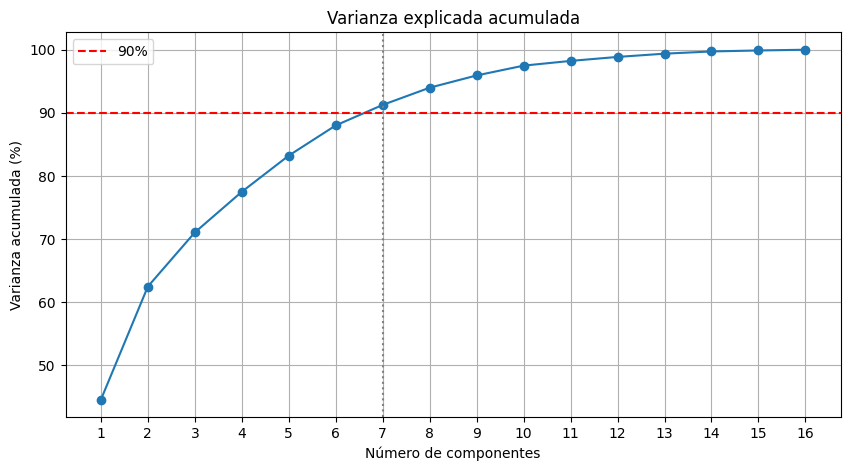

Componentes mínimos para superar el 90%: 7
Varianza acumulada con 7 componentes: 91.26%


In [24]:
acumulada = varianza.cumsum()
n_comp = int((acumulada > 90).values.argmax()) + 1

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(acumulada) + 1), acumulada, marker='o')
plt.axhline(90, color='red', linestyle='--', label='90%')
plt.axvline(n_comp, color='gray', linestyle=':')
plt.xticks(range(1, len(acumulada) + 1))
plt.title('Varianza explicada acumulada')
plt.xlabel('Número de componentes')
plt.ylabel('Varianza acumulada (%)')
plt.legend()
plt.grid(True)
plt.show()

print('Componentes mínimos para superar el 90%:', n_comp)
print(f'Varianza acumulada con {n_comp} componentes: {acumulada.iloc[n_comp - 1]:.2f}%')

Respuesta: PC1 explica 44.55% de la varianza, PC2 17.93% y PC3 8.58%. A partir de PC8 cada componente aporta menos de 3%. La curva acumulada supera el 90% en el séptimo componente (91.26%), mientras que con seis componentes se llega a 88%. Por lo tanto, el número mínimo de componentes es 7, lo que reduce los 16 predictores numéricos a 7 columnas.

8. Imprime la información de los componentes seleccionados (cargas o pesos de las variables originales) para interpretar qué variables contribuyen más a cada componente principal.
* Dibuja un diagrama de barras que muestre qué variables originales aportan más al primer componente principal (PC1), para visualizar su influencia relativa.

In [25]:
# Cargas de las variables originales en los componentes seleccionados
cargas = pd.DataFrame(pca.components_[:n_comp].T, index=X.columns, columns=pca_df.columns[:n_comp])
cargas.round(2)

,PC1,PC2,PC3,PC4,PC5,PC6,PC7
symboling,-0.10,-0.40,0.27,-0.07,-0.37,0.17,0.13
normalized_losses,0.02,-0.33,0.31,-0.34,-0.38,-0.49,-0.32
wheel_base,0.30,0.26,-0.03,-0.23,-0.00,-0.18,-0.11
length,0.34,0.14,-0.04,-0.19,-0.07,-0.08,-0.01
width,0.33,0.06,0.11,-0.10,-0.02,-0.11,0.14
height,0.11,0.42,-0.28,-0.19,-0.02,-0.21,-0.00
curb_weight,0.36,0.02,0.08,-0.03,-0.04,-0.01,0.06
num_cylinders,0.25,-0.11,0.18,0.55,0.24,-0.35,-0.07
engine_size,0.33,-0.08,0.20,0.30,0.11,0.02,-0.07
bore,0.26,0.00,-0.14,0.04,-0.37,0.51,0.13


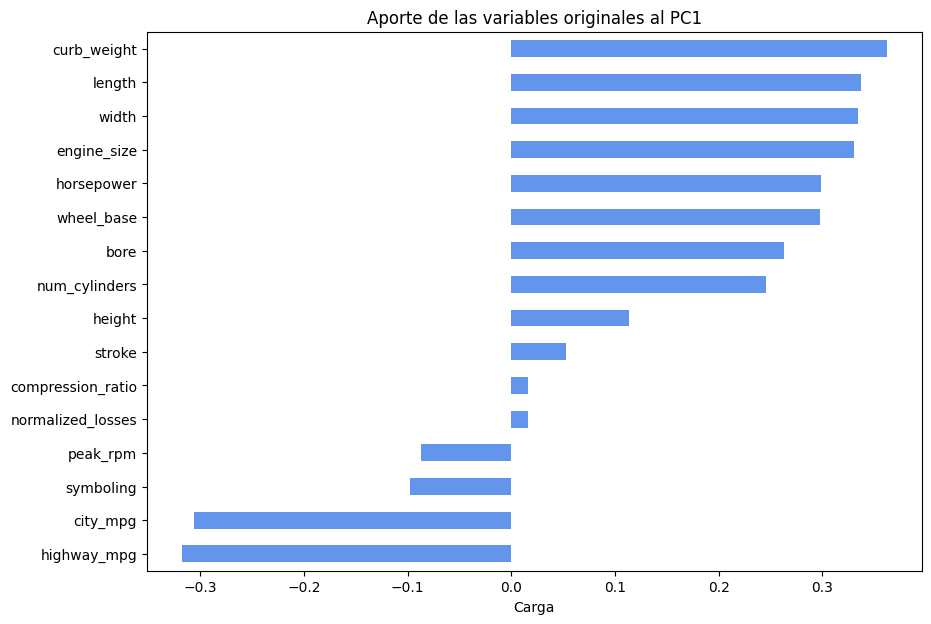

In [26]:
cargas['PC1'].sort_values().plot(kind='barh', figsize=(10, 7), color='cornflowerblue')
plt.title('Aporte de las variables originales al PC1')
plt.xlabel('Carga')
plt.show()

Interpretación de los componentes seleccionados:

- PC1 (44.55%) representa el tamaño y la potencia del auto. curb_weight (0.36), length (0.34), width (0.33), engine_size (0.33), horsepower (0.30) y wheel_base (0.30) tienen cargas positivas, mientras que city_mpg (-0.31) y highway_mpg (-0.32) tienen cargas negativas. Un valor alto de PC1 indica un auto grande, pesado y potente que rinde menos con el combustible.
- PC2 (17.93%) contrapone height (0.42) y compression_ratio (0.36) contra symboling (-0.40), peak_rpm (-0.36) y normalized_losses (-0.33), es decir, separa autos altos y de bajo riesgo de los autos de mayor riesgo para la aseguradora.
- PC3 se explica principalmente por stroke (0.51) y compression_ratio (0.49).
- PC4 por num_cylinders (0.55) contra stroke (-0.43).
- PC5 por stroke (0.57) contra normalized_losses (-0.38), symboling (-0.37) y bore (-0.37).
- PC6 por bore (0.51) contra normalized_losses (-0.49).
- PC7 por compression_ratio (0.61) y peak_rpm (0.60).

La gráfica de barras confirma que PC1 recibe aportes parecidos de las variables de tamaño y motor, que son también las más correlacionadas con el precio. Por eso este componente concentra casi la mitad de la información.

9. Codifica las variables categóricas mediante *One-Hot Encoding* y utiliza el parámetro `drop='first'` para evitar problemas de multicolinealidad entre las variables dummy generadas.

In [27]:
ohe = OneHotEncoder(drop='first', sparse_output=False)
ohe_df = pd.DataFrame(ohe.fit_transform(cars_df[cat_cols]), columns=ohe.get_feature_names_out())
print('Variables categóricas:', len(cat_cols))
print('Columnas generadas:', ohe_df.shape[1])
ohe_df.head()

Variables categóricas: 9
Columnas generadas: 44


,make_audi,make_bmw,make_chevrolet,make_dodge,make_honda,make_isuzu,make_jaguar,make_mazda,make_mercedes-benz,make_mercury,...,engine_type_ohcf,engine_type_ohcv,engine_type_rotor,fuel_system_2bbl,fuel_system_4bbl,fuel_system_idi,fuel_system_mfi,fuel_system_mpfi,fuel_system_spdi,fuel_system_spfi
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


Comprobación: Las 9 variables categóricas se transformaron en 44 columnas binarias. Como drop='first' elimina la primera categoría de cada variable, cada una genera una columna menos que su número de categorías; por ejemplo, make con 22 marcas genera 21 columnas y fuel_type solo una (fuel_type_gas). La categoría eliminada queda representada cuando todas sus columnas valen 0.

10. Conjunta, en un dataframe, las valores proyectados en los componentes seleccionados (mínimo), las transformaciones obtenidas de las variables categóricas y la variable de salida.
* Almacena el dataframe resultante en archivo.

In [28]:
final_df = pd.concat([pca_df.iloc[:, :n_comp], ohe_df, y], axis=1)
print(final_df.shape)
final_df.to_csv('automobile_pca.csv', index=False)
final_df.head()

(205, 52)


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,make_audi,make_bmw,make_chevrolet,...,engine_type_ohcv,engine_type_rotor,fuel_system_2bbl,fuel_system_4bbl,fuel_system_idi,fuel_system_mfi,fuel_system_mpfi,fuel_system_spdi,fuel_system_spfi,price
0,-0.918474,-2.397150,-0.410501,1.416623,-1.822817,1.203190,0.369729,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,13495
1,-0.918474,-2.397150,-0.410501,1.416623,-1.822817,1.203190,0.369729,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,16500
2,0.634430,-1.372747,0.872496,0.998222,1.834717,-0.774751,-0.515065,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,16500
3,-0.361470,-0.919214,0.451578,-1.489124,-0.269938,-0.789900,0.000484,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,13950
4,1.172393,-1.794960,0.183773,-1.083812,0.113486,-0.861858,-0.353900,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,17450


Conclusión: El dataframe final tiene 205 registros y 52 columnas: los 7 componentes principales, que explican 91.26% de la varianza de las variables numéricas, las 44 columnas de las variables categóricas codificadas y la variable objetivo price. Se guardó en el archivo automobile_pca.csv y queda listo para la etapa de modelado.

---

**Declaración de uso de IA**

Anthropic. (2026). Claude (Opus 5.5) [Modelo de lenguaje grande], utilizado para revisión y depuración del código, generación de código y redacción de los análisis. https://claude.ai/

---